In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [46]:
DATA_PATH = Path("../data/split_sample/train.csv")  # use ../data/split/train.csv for the full data

df = pd.read_csv(DATA_PATH)
df.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id1385950,1,2016-01-08 22:31:12,1,-73.990646,40.751068,-73.995789,40.728146,N,525
1,id1885523,2,2016-01-02 12:36:39,1,-73.982658,40.745071,-74.003258,40.732971,N,799
2,id0892204,2,2016-02-21 00:24:16,1,-73.999481,40.728580,-74.000252,40.718800,N,374
3,id2463973,2,2016-05-08 15:06:34,1,-73.977058,40.759850,-73.949989,40.776001,N,696
4,id1496105,2,2016-05-06 13:54:36,2,-73.977798,40.758221,-73.993080,40.743130,N,703


In [47]:
print(f"Shape: {df.shape} | Missing values: {df.isnull().sum().sum()} | Duplicated rows: {df.duplicated().sum()}")

Shape: (5000, 10) | Missing values: 0 | Duplicated rows: 0


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  5000 non-null   object 
 1   vendor_id           5000 non-null   int64  
 2   pickup_datetime     5000 non-null   object 
 3   passenger_count     5000 non-null   int64  
 4   pickup_longitude    5000 non-null   float64
 5   pickup_latitude     5000 non-null   float64
 6   dropoff_longitude   5000 non-null   float64
 7   dropoff_latitude    5000 non-null   float64
 8   store_and_fwd_flag  5000 non-null   object 
 9   trip_duration       5000 non-null   int64  
dtypes: float64(4), int64(3), object(3)
memory usage: 390.8+ KB


In [49]:
df.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,5000.00000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,1.52000,1.65440,-73.973659,40.751530,-73.972305,40.752438,969.608200
std,0.49965,1.29325,0.057585,0.042378,0.056861,0.045901,3616.929016
min,1.00000,1.00000,-74.177292,40.619514,-74.183403,40.575306,2.000000
25%,1.00000,1.00000,-73.991638,40.737639,-73.991266,40.735735,392.000000
50%,2.00000,1.00000,-73.981895,40.754238,-73.979771,40.754862,656.000000
75%,2.00000,2.00000,-73.967855,40.768205,-73.962240,40.770319,1066.000000
max,2.00000,6.00000,-70.851616,43.017578,-70.851616,43.017578,86329.000000


### Initial Data Quality

The dataset contains 5,000 records and 10 features. All columns are complete with no missing values.

## Trip Duration Distribution

We first examine the distribution of the target variable, `trip_duration`, to understand its spread and identify possible skewness or extreme values.

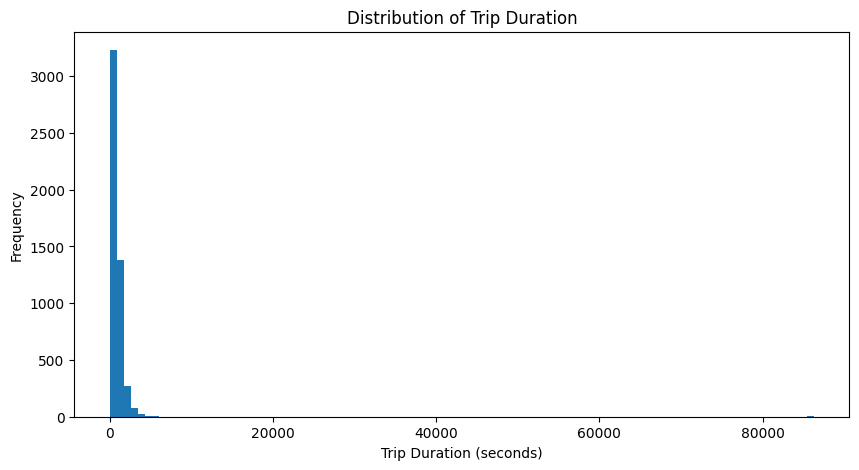

In [50]:
plt.figure(figsize=(10,5))
plt.hist(df["trip_duration"],bins=100)
plt.xlabel("Trip Duration (seconds)")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Duration")

plt.show()

### Observation

The `trip_duration` distribution is highly right-skewed. Most trips have relatively short durations, while a small number of trips have extremely large durations.

The large range of the target variable suggests the presence of extreme values and motivates examining a logarithmic transformation of the target.

In [51]:
df["log_trip_duration"] = np.log1p(df["trip_duration"])

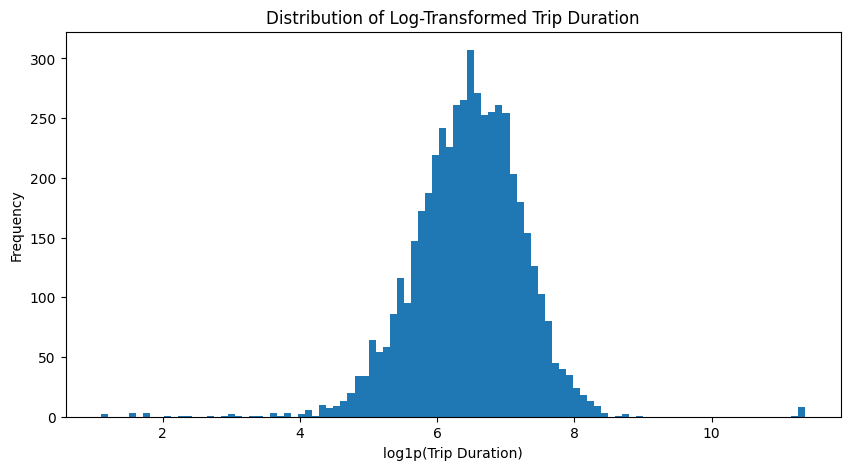

In [52]:
plt.figure(figsize=(10, 5))

plt.hist(df["log_trip_duration"], bins=100)

plt.xlabel("log1p(Trip Duration)")
plt.ylabel("Frequency")
plt.title("Distribution of Log-Transformed Trip Duration")

plt.show()

### Observation

Applying `log1p` significantly reduces the strong right skewness of `trip_duration`.
The transformed target has a more balanced distribution, making it more suitable for a linear model such as Ridge Regression.

In [53]:
df["pickup_datetime"]=pd.to_datetime(df["pickup_datetime"])

In [54]:
df["pickup_hour"]=df["pickup_datetime"].dt.hour

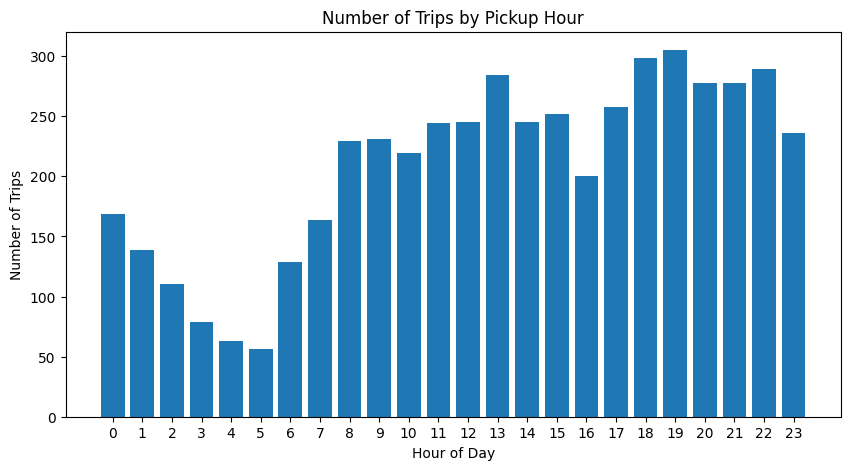

In [55]:
hour_counts=df["pickup_hour"].value_counts().sort_index()
plt.figure(figsize=(10,5))
plt.bar(hour_counts.index,hour_counts.values)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Hour")
plt.xticks(range(24))
plt.show()

### Pickup Hour Analysis

The number of taxi trips varies noticeably across the hours of the day.
The sample contains relatively fewer trips during the early morning hours, while the number of trips increases substantially during the afternoon and evening.
The highest trip activity in this sample occurs around 19:00.

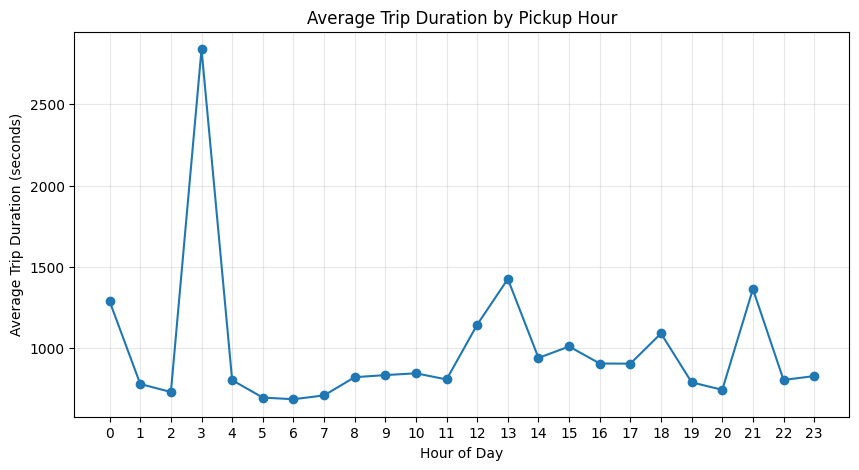

In [56]:
hour_duration=df.groupby("pickup_hour")["trip_duration"].mean()
plt.figure(figsize=(10, 5))
plt.plot(hour_duration.index, hour_duration.values, marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Average Trip Duration (seconds)")
plt.title("Average Trip Duration by Pickup Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

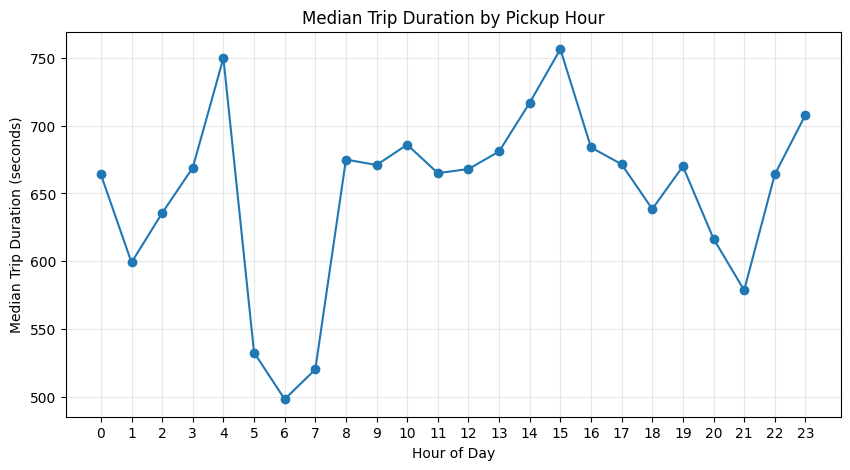

In [57]:
hour_median = df.groupby("pickup_hour")["trip_duration"].median()

plt.figure(figsize=(10, 5))

plt.plot(hour_median.index, hour_median.values, marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Median Trip Duration (seconds)")
plt.title("Median Trip Duration by Pickup Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

### Trip Duration by Pickup Hour

The mean trip duration varies across pickup hours, but some large variations may be affected by extreme trip durations, especially for hours with fewer observations.

Using the median provides a more robust view of the typical trip duration across different hours.

### Decision: Pickup Hour

The median duration is lowest in the early morning (about 498 s at 06:00) and highest in the afternoon (about 756 s at 15:00), a difference of roughly 50%. The pattern rises and falls during the day, so a single linear term (`hour` as a number) cannot represent it.

**Feature idea:** treat `hour` as categorical (one-hot), and test a rush-hour flag and a cyclic (sin/cos) encoding as alternatives.

In [58]:
df["pickup_dayofweek"] = df["pickup_datetime"].dt.dayofweek

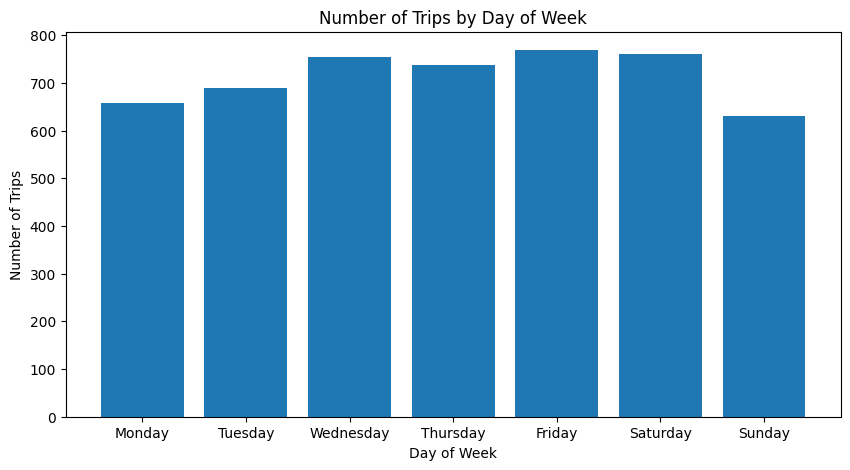

In [59]:
day_counts = df["pickup_dayofweek"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(day_counts.index, day_counts.values)

plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Day of Week")
plt.xticks(range(7), [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

plt.show()

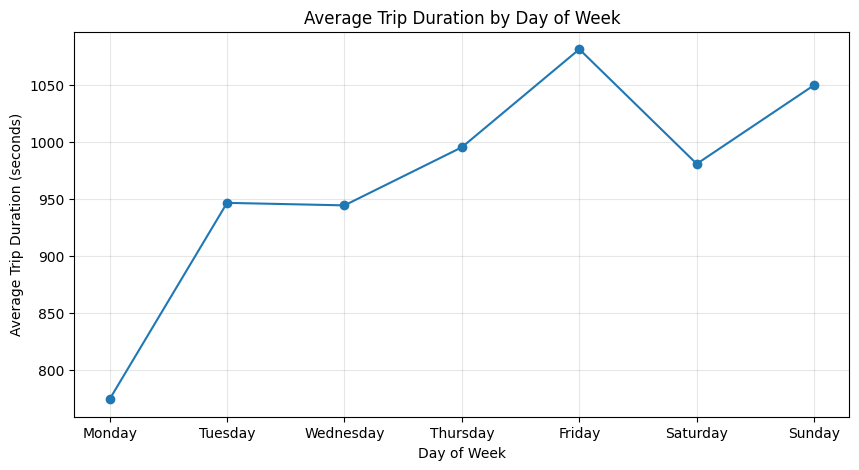

In [60]:
day_duration = df.groupby("pickup_dayofweek")["trip_duration"].mean()

plt.figure(figsize=(10, 5))
plt.plot(day_duration.index, day_duration.values, marker="o")

plt.xlabel("Day of Week")
plt.ylabel("Average Trip Duration (seconds)")
plt.title("Average Trip Duration by Day of Week")
plt.xticks(range(7), [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])
plt.grid(alpha=0.3)

plt.show()

### Median Trip Duration by Day of Week

Since the mean trip duration can be affected by extreme values, the median is used to provide a more robust comparison of typical trip duration across different days of the week.

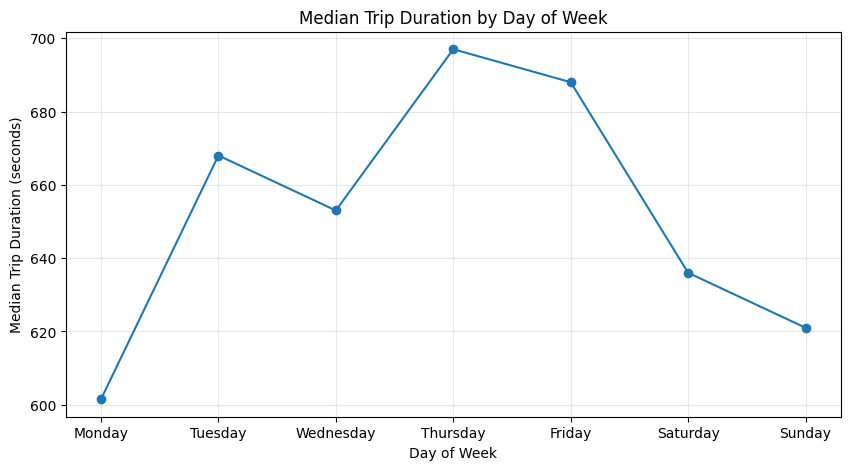

In [61]:
day_median = df.groupby("pickup_dayofweek")["trip_duration"].median()

plt.figure(figsize=(10, 5))

plt.plot(day_median.index, day_median.values, marker="o")

plt.xlabel("Day of Week")
plt.ylabel("Median Trip Duration (seconds)")
plt.title("Median Trip Duration by Day of Week")

plt.xticks(
    range(7),
    [
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]
)

plt.grid(alpha=0.3)

plt.show()

### Decision: Day of Week

Trip counts are lowest on Sunday (631) and highest on Friday (769). Median duration is shortest on Monday (about 602 s) and longest on Thursday (about 697 s), roughly a 16% difference. The effect is smaller than the hour effect but visible.

**Feature idea:** `dayofweek` as categorical, plus a weekend flag as a simpler alternative.

## Pickup Month Analysis

The pickup date can provide information about seasonal patterns in taxi demand and trip duration.

We extract the month from `pickup_datetime` and examine the number of trips and typical trip duration across different months.

In [62]:
df["pickup_month"] = df["pickup_datetime"].dt.month

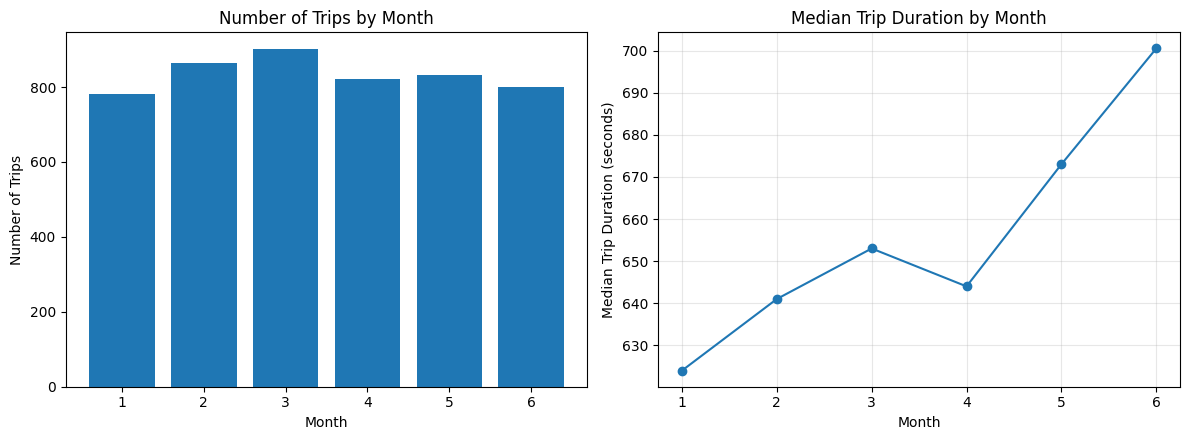

In [63]:
month_counts = df["pickup_month"].value_counts().sort_index()
month_median = df.groupby("pickup_month")["trip_duration"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(month_counts.index, month_counts.values)
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Trips")
axes[0].set_title("Number of Trips by Month")

axes[1].plot(month_median.index, month_median.values, marker="o")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Median Trip Duration (seconds)")
axes[1].set_title("Median Trip Duration by Month")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observation

The data covers only January to June 2016, with a fairly balanced number of trips per month (781 to 901). The median duration rises from about 624 s in January to about 700 s in June, with a small dip in April. This is consistent with a gradual seasonal trend (more traffic and tourism in warmer months).

**Caution:** because the data contains only six months, `month` cannot be extrapolated to other periods. It is acceptable here because the test set comes from the same period. We will test it as a feature and keep it only if it improves validation R².

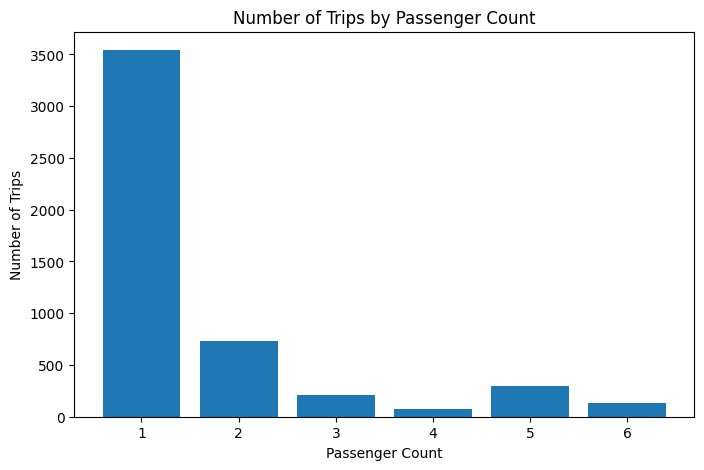

In [64]:
passenger_counts = df["passenger_count"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(passenger_counts.index, passenger_counts.values)

plt.xlabel("Passenger Count")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Passenger Count")
plt.xticks(passenger_counts.index)

plt.show()

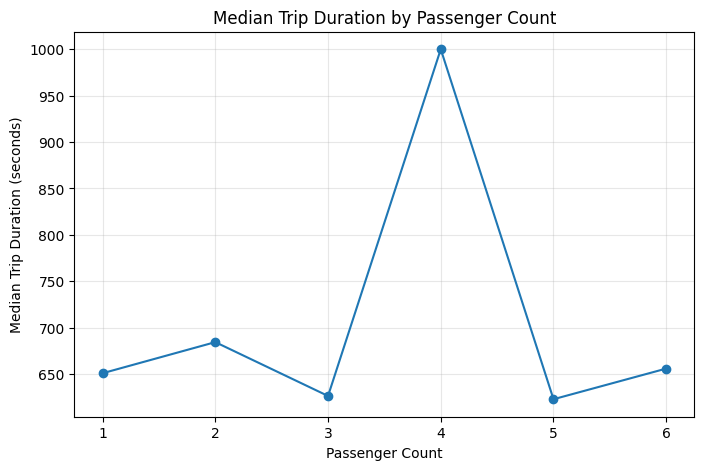

In [65]:
passenger_duration = df.groupby("passenger_count")["trip_duration"].median()

plt.figure(figsize=(8, 5))

plt.plot(passenger_duration.index, passenger_duration.values, marker="o")

plt.xlabel("Passenger Count")
plt.ylabel("Median Trip Duration (seconds)")
plt.title("Median Trip Duration by Passenger Count")
plt.xticks(passenger_duration.index)
plt.grid(alpha=0.3)

plt.show()

### Passenger Count Analysis

Most trips in the sample have one passenger, while trips with higher passenger counts are less frequent.

The median trip duration varies across passenger counts, with four-passenger trips showing the highest median duration in this sample. However, the number of observations for higher passenger counts is much smaller, so this difference should be interpreted cautiously.

In [66]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in kilometers

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c

df["distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)
df["log_distance_km"] = np.log1p(df["distance_km"])

df["distance_km"].describe()

count    5000.000000
mean        3.413393
std         3.877821
min         0.000000
25%         1.245019
50%         2.100697
75%         3.832181
max        42.353672
Name: distance_km, dtype: float64

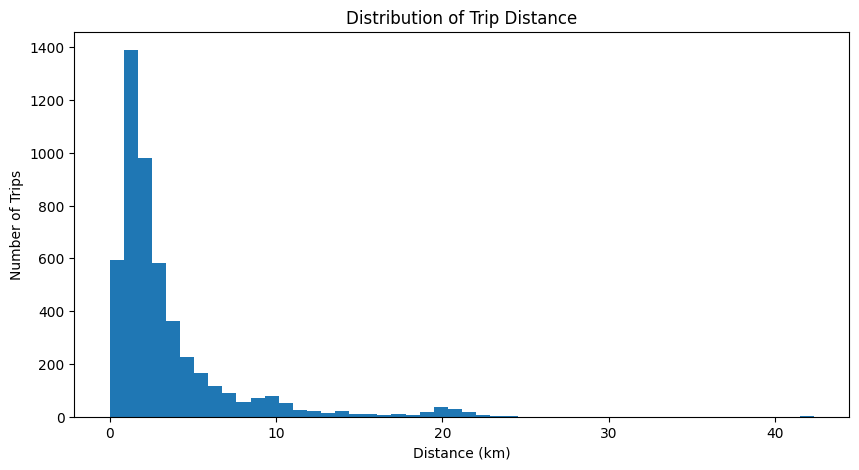

In [67]:
plt.figure(figsize=(10, 5))

plt.hist(df["distance_km"], bins=50)

plt.xlabel("Distance (km)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distance")

plt.show()

In [68]:
df[[
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude",
    "distance_km",
    "trip_duration"
]].sort_values("distance_km", ascending=False).head(10)

,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,distance_km,trip_duration
2247,40.775799,-73.950462,41.084320,-73.654800,42.353672,85828
63,40.648720,-73.783699,40.840260,-73.923637,24.343294,2984
3653,40.641117,-73.788872,40.824944,-73.944221,24.272490,1914
3200,40.645416,-73.776680,40.802074,-73.968254,23.750214,2840
987,40.791264,-73.968758,40.644924,-73.776573,22.959157,2231
4543,40.761009,-73.998238,40.645199,-73.776421,22.703798,3422
2376,40.646149,-73.780533,40.773178,-73.990334,22.632541,2021
3538,40.643421,-73.789513,40.784859,-73.981750,22.580040,4531
3774,40.644459,-73.782616,40.778019,-73.984184,22.565490,2690
1004,40.645187,-73.792099,40.793682,-73.972336,22.435833,2705


### Observation: Trip Distance

Distances are strongly right-skewed: the median trip is about 2.1 km, the 99th percentile about 20.6 km, and the maximum about 42.4 km. A few very long trips would dominate a linear model.

**Feature idea:** use `log1p(distance_km)` instead of (or next to) the raw distance. A log-scaled distance is also more natural for a log-scaled target.

## Trip Speed Analysis

Average trip speed is calculated from the geographic distance and trip duration.

This feature is mainly used during EDA to identify potentially anomalous trips where the recorded duration is unusually short or long relative to the geographic distance.

In [69]:
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)
df["speed_kmh"].describe()

count    5000.000000
mean       14.633276
std         8.539277
min         0.000000
25%         9.327454
50%        12.885584
75%        18.146247
max       239.631912
Name: speed_kmh, dtype: float64

In [70]:
df[[
    "distance_km",
    "trip_duration",
    "speed_kmh"
]].sort_values("speed_kmh", ascending=False).head(10)

,distance_km,trip_duration,speed_kmh
1505,0.665644,10,239.631912
1162,0.102707,5,73.949025
1136,5.311782,263,72.708800
371,12.371676,717,62.117203
4917,16.301238,969,60.561875
456,0.065797,4,59.217672
232,19.973493,1311,54.847121
2369,17.366996,1164,53.712359
4142,19.418784,1319,53.000473
3224,15.581962,1070,52.425294


### Observation

The speed distribution contains several unusually high values. These observations may indicate anomalous trip durations or unusual records and should be investigated before deciding how to handle them.

The identified extreme values are retained during EDA rather than being removed automatically.

## Distance and Trip Duration Analysis

The geographic distance between the pickup and dropoff locations may have a relationship with trip duration.

To investigate this relationship, we calculate the Haversine distance between the pickup and dropoff coordinates and analyze how trip duration changes with distance.

We also examine the relationship using the log-transformed trip duration because the original target contains strong right skewness and extreme values.

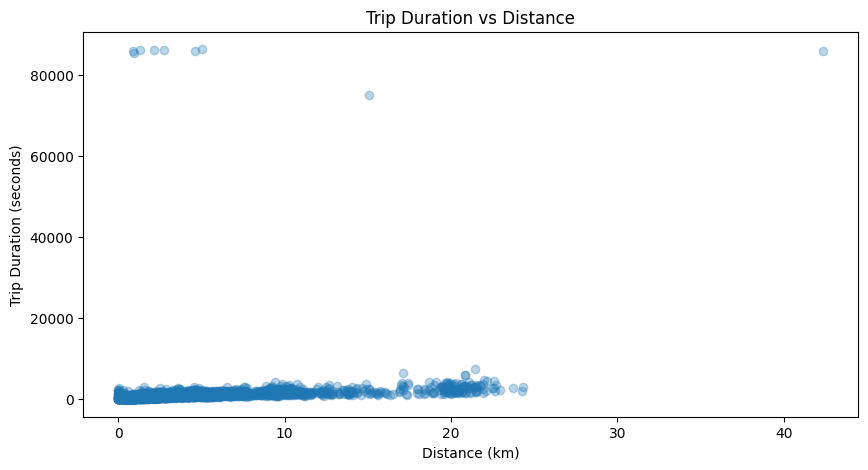

In [71]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["distance_km"],
    df["trip_duration"],
    alpha=0.3
)

plt.xlabel("Distance (km)")
plt.ylabel("Trip Duration (seconds)")
plt.title("Trip Duration vs Distance")

plt.show()

### Log-Transformed Trip Duration

The relationship is also visualized using the log-transformed trip duration to reduce the influence of extreme trip durations and obtain a clearer view of the relationship with distance.

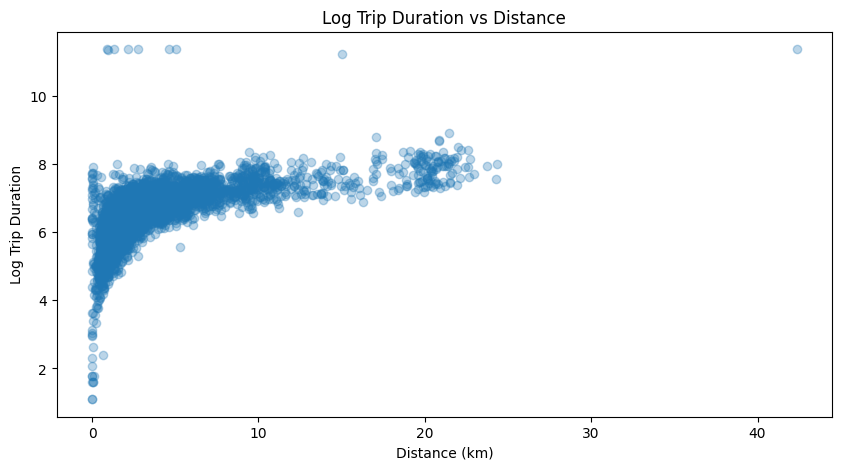

In [72]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["distance_km"],
    df["log_trip_duration"],
    alpha=0.3
)

plt.xlabel("Distance (km)")
plt.ylabel("Log Trip Duration")
plt.title("Log Trip Duration vs Distance")

plt.show()

### Observation: Distance vs Duration

On the raw duration scale a few points with durations near 24 hours cannot be explained by any distance and stretch the plot. On the log scale the cloud is much tighter, but the relationship is clearly **concave**: duration rises quickly for short distances and flattens for long ones. This is exactly the shape a log-transformed distance straightens out. The log-log version of this plot, with the anomalies highlighted, is shown in the next section.

## Outlier Detection and Cleaning Rules

The previous sections showed anomalies in duration, speed and coordinates. Here we turn them into explicit, countable rules, so the cleaning step in the training code is justified by evidence rather than guesses.

The rules are only **flagged** here; no rows are removed from `df`.

In [73]:
lon_lo, lon_hi = -74.3, -73.7
lat_lo, lat_hi = 40.5, 41.0

in_nyc = (
    df["pickup_longitude"].between(lon_lo, lon_hi)
    & df["dropoff_longitude"].between(lon_lo, lon_hi)
    & df["pickup_latitude"].between(lat_lo, lat_hi)
    & df["dropoff_latitude"].between(lat_lo, lat_hi)
)

rules = {
    "Duration < 10 s": df["trip_duration"] < 10,
    "Duration > 6 h": df["trip_duration"] > 6 * 3600,
    "Coordinates outside NYC box": ~in_nyc,
    "Speed > 100 km/h": df["speed_kmh"] > 100,
    "Same place (< 50 m) but > 10 min": (df["distance_km"] < 0.05) & (df["trip_duration"] > 600),
}

df["is_outlier"] = pd.concat(rules.values(), axis=1).any(axis=1)

rule_table = pd.Series({name: int(mask.sum()) for name, mask in rules.items()}, name="n_trips").to_frame()
rule_table.loc["Any rule (union)"] = int(df["is_outlier"].sum())
rule_table["pct_of_trips"] = (100 * rule_table["n_trips"] / len(df)).round(2)
rule_table

,n_trips,pct_of_trips
Duration < 10 s,10,0.20
Duration > 6 h,9,0.18
Coordinates outside NYC box,3,0.06
Speed > 100 km/h,1,0.02
Same place (< 50 m) but > 10 min,13,0.26
Any rule (union),34,0.68


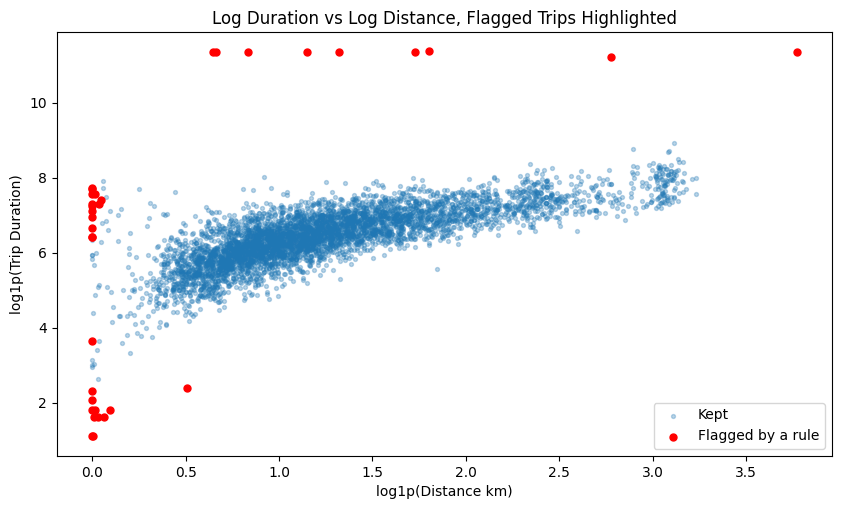

Trips lasting between 3 h and 22 h: 1
Correlation (log distance vs log duration): all trips = 0.736 | after removing flagged = 0.778


In [74]:
fig, ax = plt.subplots(figsize=(10, 5.5))

normal = df[~df["is_outlier"]]
flagged = df[df["is_outlier"]]

ax.scatter(normal["log_distance_km"], normal["log_trip_duration"], s=8, alpha=0.3, label="Kept")
ax.scatter(flagged["log_distance_km"], flagged["log_trip_duration"], s=25, color="red", label="Flagged by a rule")

ax.set_xlabel("log1p(Distance km)")
ax.set_ylabel("log1p(Trip Duration)")
ax.set_title("Log Duration vs Log Distance, Flagged Trips Highlighted")
ax.legend()
plt.show()

corr_all = df["log_distance_km"].corr(df["log_trip_duration"])
corr_clean = normal["log_distance_km"].corr(normal["log_trip_duration"])
n_mid = df["trip_duration"].between(3 * 3600, 22 * 3600).sum()
print(f"Trips lasting between 3 h and 22 h: {n_mid}")
print(f"Correlation (log distance vs log duration): all trips = {corr_all:.3f} | after removing flagged = {corr_clean:.3f}")

### Observation

The five rules flag 34 trips (0.68% of the sample).

- **The long-duration cut-off is not sensitive.** Only one trip lasts between 3 and 22 hours (about 20 h, itself an obvious error), so any cut-off between 3 h and 20 h flags the same 9 trips. We use 6 h. Trips under 10 seconds are cancelled or mis-recorded rides.
- **Speed and same-place rules** catch records where duration and geography contradict each other (for example, a long wait at almost zero distance).
- **Impact:** removing the flagged trips raises the correlation between log distance and log duration from 0.736 to 0.778, so these rows weaken the signal the model needs.

**Decision:** apply these rules to the **training set only**. Validation and test sets stay untouched, because the hidden test set will contain such rows too and we cannot remove them at prediction time.

## Geographic Analysis

We look at where trips start and end, and test whether the two airports (JFK and LaGuardia) behave differently from ordinary city trips. Only trips inside the NYC bounding box are plotted so the few far-away points do not squash the map.

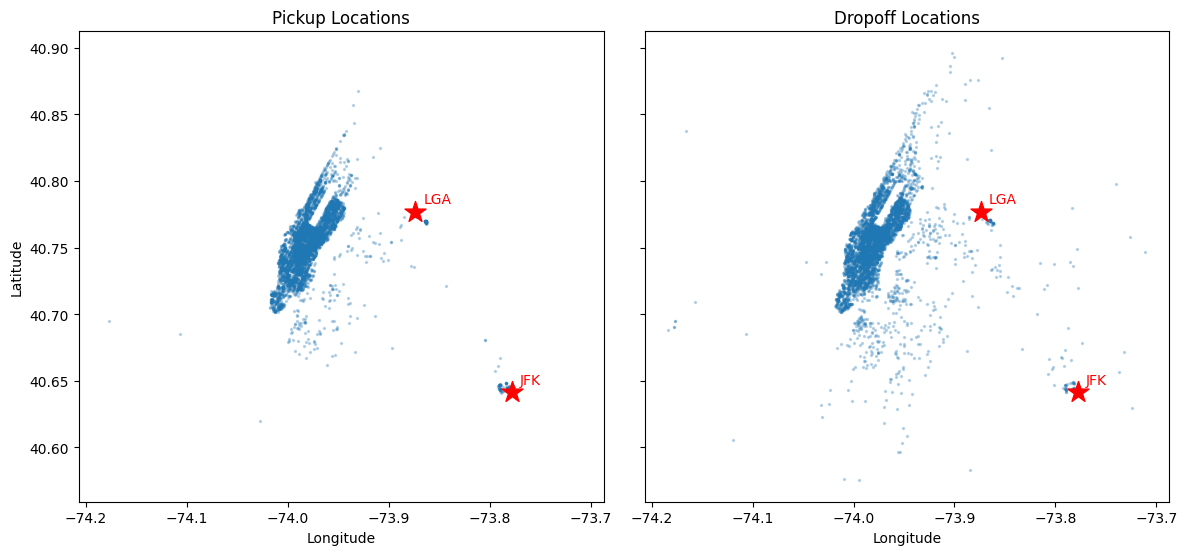

In [75]:
airports = {"JFK": (40.6413, -73.7781), "LGA": (40.7769, -73.8740)}
city = df[in_nyc]

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
panels = [("pickup_longitude", "pickup_latitude", "Pickup Locations"),
          ("dropoff_longitude", "dropoff_latitude", "Dropoff Locations")]

for ax, (lon, lat, title) in zip(axes, panels):
    ax.scatter(city[lon], city[lat], s=2, alpha=0.25)
    for name, (a_lat, a_lon) in airports.items():
        ax.scatter(a_lon, a_lat, marker="*", s=250, color="red", zorder=3)
        ax.annotate(name, (a_lon, a_lat), xytext=(6, 6), textcoords="offset points", color="red")
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_aspect(1 / np.cos(np.radians(40.75)))
axes[0].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [76]:
# A trip is an "airport trip" if its pickup or dropoff is within 2 km of the airport
df["airport_trip"] = "Other"
for name, (a_lat, a_lon) in airports.items():
    near = (
        (haversine_distance(df["pickup_latitude"], df["pickup_longitude"], a_lat, a_lon) < 2)
        | (haversine_distance(df["dropoff_latitude"], df["dropoff_longitude"], a_lat, a_lon) < 2)
    )
    df.loc[near, "airport_trip"] = name

airport_summary = df.groupby("airport_trip").agg(
    n_trips=("trip_duration", "size"),
    median_duration_s=("trip_duration", "median"),
    median_distance_km=("distance_km", "median"),
).round(1)
airport_summary

,n_trips,median_duration_s,median_distance_km
airport_trip,,,
JFK,132,2413.5,20.1
LGA,184,1629.0,9.6
Other,4684,624.5,2.0


### Observation

Pickups are concentrated almost entirely in Manhattan, with two tight clusters at the airports. Dropoffs are much more spread out across Brooklyn, Queens and beyond, which makes sense: passengers hail taxis in Manhattan but travel anywhere.

Airport trips are very different from ordinary trips: the median JFK trip lasts about 2,414 s (about 20 km) and the median LGA trip about 1,629 s (about 10 km), against about 625 s for all other trips. Part of this is simply distance. Whether an airport flag adds information **beyond** distance (highway driving, tolls, airport queues) is a hypothesis to test in the modeling stage, not something we can claim from this table.

**Feature idea:** distance-to-airport features or JFK/LGA flags, and spatial clusters (KMeans on pickup and dropoff coordinates) so the linear model can learn zone effects. Raw latitude and longitude are weak linear predictors on their own (see the next section).

## Correlation Analysis

Correlation analysis is used to examine the linear relationships between numerical features and the target variable.

It can help identify features that may contain useful information for predicting trip duration. However, correlation measures only linear relationships, so a low correlation does not necessarily mean that a feature is unimportant.

In [77]:
feature_cols = [
    "vendor_id", "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "distance_km", "log_distance_km",
]

corr_table = pd.DataFrame({
    "corr_with_trip_duration": df[feature_cols].corrwith(df["trip_duration"]),
    "corr_with_log_trip_duration": df[feature_cols].corrwith(df["log_trip_duration"]),
}).round(3)

corr_table

,corr_with_trip_duration,corr_with_log_trip_duration
vendor_id,0.040,0.024
passenger_count,0.016,0.028
pickup_longitude,0.028,0.125
pickup_latitude,-0.044,-0.093
dropoff_longitude,0.062,0.117
dropoff_latitude,-0.008,-0.088
distance_km,0.185,0.622
log_distance_km,0.158,0.736


### Observation

The correlation was recomputed against **both** the raw and the log-transformed target. The model is trained on `log1p(trip_duration)`, so the second column is the one that matters.

- Against the raw duration, `distance_km` shows only 0.185. This low value is an artifact of the extreme durations (roughly 24-hour trips), not evidence of a weak relationship.
- Against the log target, `distance_km` rises to about 0.62, and `log_distance_km` reaches **0.736** (0.778 after removing the flagged outliers). **Distance is by far the strongest feature.**
- `vendor_id` (0.024) and `passenger_count` (0.028) are almost uncorrelated with the log target.
- The four raw coordinates are individually weak (absolute correlation around 0.09 to 0.13), but they carry location information that a linear model cannot use directly. Zone clusters or airport features are a better way to encode it.

Correlation measures linear relationships only, so a low value does not rule a feature out; it tells us how to prioritize.

## Vendor Analysis

The `vendor_id` feature identifies the taxi service provider associated with each trip.

We first examine the number of trips recorded for each vendor and then compare their typical trip durations.

In [78]:
vendor_counts = df["vendor_id"].value_counts().sort_index()

vendor_counts

vendor_id
1    2400
2    2600
Name: count, dtype: int64

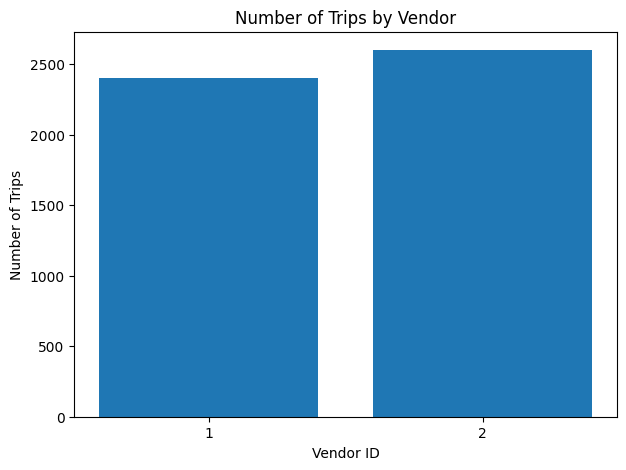

In [79]:
plt.figure(figsize=(7, 5))

plt.bar(
    vendor_counts.index.astype(str),
    vendor_counts.values
)

plt.xlabel("Vendor ID")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Vendor")

plt.show()

In [80]:
vendor_median = (
    df.groupby("vendor_id")["trip_duration"]
    .median()
)

vendor_median

vendor_id
1    656.0
2    655.5
Name: trip_duration, dtype: float64

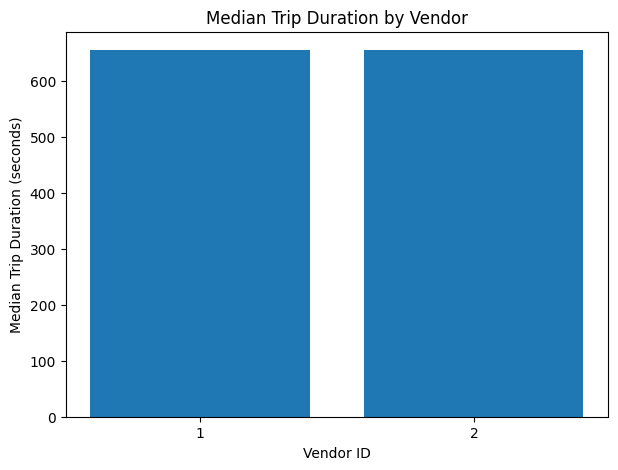

In [81]:
plt.figure(figsize=(7, 5))

plt.bar(
    vendor_median.index.astype(str),
    vendor_median.values
)

plt.xlabel("Vendor ID")
plt.ylabel("Median Trip Duration (seconds)")
plt.title("Median Trip Duration by Vendor")

plt.show()

### Observation

The two taxi vendors have a relatively balanced number of recorded trips, with 2,400 trips for Vendor 1 and 2,600 trips for Vendor 2.

The median trip duration is nearly identical for both vendors, at approximately 656 seconds. Therefore, no substantial difference in typical trip duration is observed between the two vendors in this sample.

## Store and Forward Flag Analysis

The `store_and_fwd_flag` indicates whether the trip record was stored in the vehicle before being forwarded to the system.

We examine its distribution and compare the typical trip duration between the two categories.

In [82]:
flag_counts = df["store_and_fwd_flag"].value_counts().sort_index()

flag_counts

store_and_fwd_flag
N    4964
Y      36
Name: count, dtype: int64

### Trip Duration by Store-and-Forward Flag

The `store_and_fwd_flag` feature is highly imbalanced, with most trips belonging to the `N` category.

We compare the median trip duration between the two categories to investigate whether stored-and-forwarded trips show a different typical duration.

In [83]:
flag_median = (
    df.groupby("store_and_fwd_flag")["trip_duration"].median())

flag_median

store_and_fwd_flag
N    655.5
Y    741.5
Name: trip_duration, dtype: float64

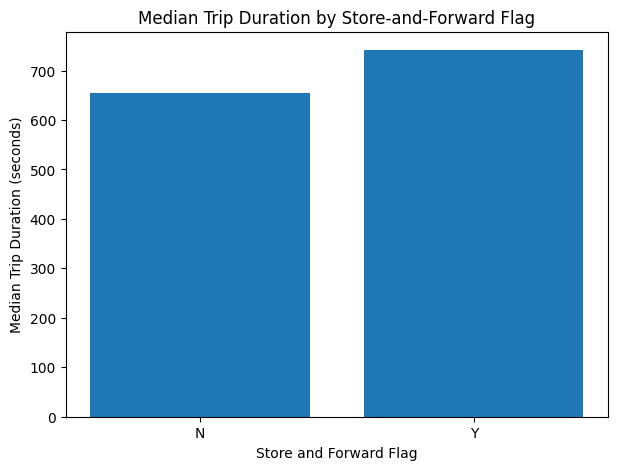

In [84]:
plt.figure(figsize=(7, 5))

plt.bar(
    flag_median.index,
    flag_median.values
)

plt.xlabel("Store and Forward Flag")
plt.ylabel("Median Trip Duration (seconds)")
plt.title("Median Trip Duration by Store-and-Forward Flag")

plt.show()

### Observation

The `store_and_fwd_flag` feature is highly imbalanced, with 4,964 trips labeled `N` and only 36 trips labeled `Y`.

The median trip duration is 655.5 seconds for `N` trips and 741.5 seconds for `Y` trips. Although `Y` trips have a higher median duration in this sample, the very small number of `Y` observations makes this difference difficult to interpret reliably.

## Summary of Findings and Decisions

| Area | Finding | Decision |
|---|---|---|
| Target | Strongly right-skewed, extreme values up to about 24 h | Train on `log1p(trip_duration)` |
| Outliers | 34 trips (0.68%) flagged by five rules; no trips between 3 h and 20 h except one error | Remove them from the **training set only** |
| Distance | Strongest signal: correlation 0.736 with the log target (0.778 after cleaning) | Haversine distance, log-transformed |
| Hour | Non-monotonic: about 498 s at 06:00 to about 756 s at 15:00 | One-hot hour; test rush-hour flag and sin/cos |
| Day of week | Median about 602 s (Mon) to about 697 s (Thu) | One-hot day; test weekend flag |
| Month | Median rises from about 624 s to about 700 s from Jan to Jun | Test as a feature; data covers six months only |
| Location | Raw coordinates are weak linearly; airports are very different (JFK about 2,414 s, LGA about 1,629 s) | KMeans zones and airport flags/distances |
| Linear model | Ridge cannot learn interactions on its own | Test interactions such as distance x hour and distance x airport |
| Vendor, passenger count | Correlation with the log target below 0.03 | Low priority; keep only if validation R² improves |
| `store_and_fwd_flag` | Only 36 `Y` trips | Too little data to judge; low priority |

**Avoid:** one-hot encoding `dayofyear` (about 180 columns for 4,000 rows invites overfitting; the warm-start baseline already showed negative R² on this sample).

**Next step:** build the cleaning and feature code in `src/` following this table, and add features one at a time, tracking validation R² after each.

## Validation on the Full Training Data

The exploration above used the 5,000-row sample for speed. Here the key findings are re-checked on the full training set (about 1 million trips) before they are frozen into the model. The cleaning rules and the feature code are imported from the project's `src` package, so the notebook and the training script use exactly the same logic.

In [85]:
import sys
sys.path.append(str(Path("..").resolve()))   # lets the notebook import the project's src package
from src.cleaning import outlier_mask
from src.features import add_features

FULL_PATH = Path("../data/split/train.csv")

full = pd.read_csv(FULL_PATH, parse_dates=["pickup_datetime"])
full["log_trip_duration"] = np.log1p(full["trip_duration"])
full = add_features(full)                     # hour, dayofweek, dayofyear, distance, airport flags
full["is_outlier"] = outlier_mask(full)

clean = full[~full["is_outlier"]]
corr_all = full["log_distance_km"].corr(full["log_trip_duration"])
corr_clean = clean["log_distance_km"].corr(clean["log_trip_duration"])

print(f"Rows: {len(full):,} | outliers: {full['is_outlier'].sum():,} ({100 * full['is_outlier'].mean():.2f}%)")
print(f"Correlation (log distance vs log duration): all = {corr_all:.3f} | after removing outliers = {corr_clean:.3f}")

Rows: 1,000,000 | outliers: 5,290 (0.53%)
Correlation (log distance vs log duration): all = 0.750 | after removing outliers = 0.781


### Observation: The Cleaning Rules on the Full Data

The five cleaning rules flag **5,290 of 1,000,000 trips (0.53%)**, which is close to the 0.68% found in the 5,000-row sample. The rules therefore carry over to the full data and remove only a small fraction of the trips.

The correlation between log distance and log duration is **0.750** on all trips and **0.781** after removing the flagged ones (0.736 and 0.778 in the sample). The two sets of numbers agree, so the conclusions drawn from the sample were not an accident of its small size. Distance is by far the strongest single signal, and the flagged rows weaken it.

In [86]:
full["airport_trip"] = np.select([full["is_jfk"] == 1, full["is_lga"] == 1], ["JFK", "LGA"], default="Other")

clean = full[~full["is_outlier"]]
clean.groupby("airport_trip").agg(
    n_trips=("trip_duration", "size"),
    median_duration_s=("trip_duration", "median"),
    median_distance_km=("distance_km", "median"),
).round(1)

,n_trips,median_duration_s,median_distance_km
airport_trip,,,
JFK,28382,2394.0,20.1
LGA,36998,1636.0,9.6
Other,929330,624.0,2.0


### Observation: Airports on the Full Data

Airport trips are about 6.6% of all trips (28,382 for JFK and 36,998 for LGA) and they behave very differently from ordinary trips:

| | Median duration | Median distance | Implied average speed |
|---|---|---|---|
| JFK | 2,394 s | 20.1 km | about 30 km/h |
| LGA | 1,636 s | 9.6 km | about 21 km/h |
| Other | 624 s | 2.0 km | about 11.5 km/h |

(The implied speed is the median distance divided by the median duration, so it is only a rough guide.)

A JFK trip lasts about 3.8 times longer than a typical trip and an LGA trip about 2.6 times longer. Most of this is distance, but airport trips are also **faster per kilometre** (highways instead of city streets). A model that only knows the distance would therefore misjudge them, which is the reason to give it an explicit airport indicator. These numbers match what the 5,000-row sample suggested.

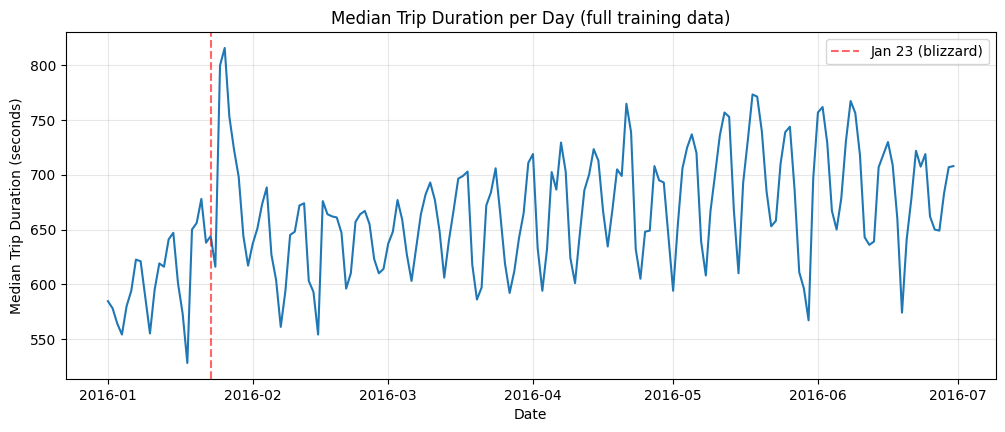

pickup_datetime
2016-05-15    122.0
2016-05-30    120.0
2016-01-18    119.0
2016-02-15    108.0
2016-06-19    104.0
Name: trip_duration, dtype: float64

In [87]:
clean = full[~full["is_outlier"]]
daily = clean.groupby(clean["pickup_datetime"].dt.date)["trip_duration"].median()
daily.index = pd.to_datetime(daily.index)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.values)
ax.axvline(pd.Timestamp("2016-01-23"), color="red", linestyle="--", alpha=0.6, label="Jan 23 (blizzard)")
ax.set_xlabel("Date")
ax.set_ylabel("Median Trip Duration (seconds)")
ax.set_title("Median Trip Duration per Day (full training data)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# the 5 days that differ most from their weekly median
unusual = (daily - daily.rolling(7, center=True, min_periods=1).median()).abs().sort_values(ascending=False).head(5)
unusual.round(0)

## Summary of Findings and Decisions

| Area | Finding | Decision |
|---|---|---|
| Target | Strongly right-skewed, extreme values up to about 24 h | Use `log1p(trip_duration)` |
| Outliers | 5,290 of 1,000,000 trips (0.53%) flagged by five rules (sample: 34 of 5,000) | Remove them from the **training set only** |
| Distance | Strongest signal: correlation with the log target 0.750 on the full data, 0.781 after removing outliers | Haversine distance, log-transformed |
| Hour | Non-monotonic: about 498 s at 06:00 to about 756 s at 15:00 (sample) | One-hot hour |
| Day of week | A weekly cycle of roughly 100 s is visible on the full data | One-hot day of week |
| Calendar day | Slow upward trend from January to June; sharp drops on holidays; a peak right after the Jan 23 blizzard | Day of year as a categorical feature (works only for this period, not another year) |
| Location | Raw coordinates are weak linearly; airport trips are 6.6% of trips and very different (JFK 2,394 s, LGA 1,636 s, others 624 s) and faster per km | KMeans zones and airport indicators |
| Linear model | Ridge cannot learn interactions on its own | Add interaction-style features such as pickup zone × dropoff zone (route) |
| Vendor, passenger count | Correlation with the log target below 0.03 | Low priority |
| `store_and_fwd_flag` | Only 36 `Y` trips in the sample | Too few to judge; low priority |

**Avoid:** one-hot encoding the day of year on the 5,000-row sample (about 180 columns for 4,000 rows invites overfitting). On the full data, with about 5,500 trips per day, it is safe.

The final feature set and the modeling results are documented in the project report.